# Online variance and testing

Compute the population variance after each reading without losing its small variation around a large baseline.

The raw second moment minus the squared mean is mathematically correct but can cancel numerically. Welford updates a running mean and a sum of squared deviations. A two-pass calculation on each short prefix gives a separate check. The population denominator is the prefix length. A sample variance would use one fewer and be undefined on the first observation.

Zero member initialisers establish a valid empty accumulator. Updating the object changes only its own state.

In [1]:
from pathlib import Path
import sys, math, statistics
import numpy as np
import matplotlib.pyplot as plt

here = Path.cwd()
sys.path.insert(0, str(here.parent.parent))
from course_runner import run_native

## Native source

`native.cpp`

```cpp
#include <iostream>
#include <iomanip>

struct Moments {
    unsigned count{};
    double mean{}, m2{};
    double update(double x) {
        double delta = x - mean;
        mean += delta / ++count;
        m2 += delta * (x - mean);
        return m2 / count;
    }
};

int main() {
    std::cout << std::setprecision(12);
    Moments state;
    for (double x : {1., 2., 4., 5.}) std::cout << state.update(1e9 + x) << ' ';
}
```

## Execute the native listing

Zero member initialisers establish a valid empty accumulator. Updating the object changes only its own state. Look at the lifetime of each object and the owner of its storage. Passing a const reference permits observation without copying the container. Algorithms operate on half-open iterator ranges.

In [2]:
x = [1_000_000_000 + i for i in (1, 2, 4, 5)]
expected = np.asarray([statistics.pvariance(x[:i]) for i in range(1, len(x) + 1)], dtype=float)
engine, stdout = run_native(here / "native.cpp")
observed = np.asarray([float(v) for v in stdout.split()])
assert observed.shape == expected.shape
np.testing.assert_allclose(observed, expected, rtol=2e-7, atol=2e-7)
print("Runtime:", engine)
print("Native stdout:", stdout.strip())
print("Largest absolute difference:", f"{np.max(np.abs(observed-expected)):.3g}")

Runtime: C++
Native stdout: 0 0.25 1.55555552244 2.4999999553
Largest absolute difference: 4.47e-08


## Read the output

The first variance is zero. Subsequent variances describe the spread seen so far, and shifting every input by a constant preserves them in exact arithmetic. The marks show the independent Python reference at each position.

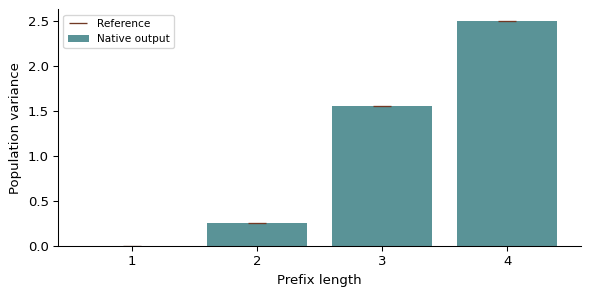

In [3]:
labels = ["1", "2", "3", "4"]
positions = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(6.1, 3), constrained_layout=True)
ax.bar(positions, observed, color="#367b80", alpha=0.82, label="Native output")
ax.plot(
    positions,
    expected,
    linestyle="none",
    marker="_",
    markersize=13,
    color="#713925",
    label="Reference",
)
ax.set(xticks=positions, xticklabels=labels, xlabel="Prefix length", ylabel="Population variance")
ax.legend(fontsize=8)
plt.show()

## Interpreting the result

The first variance is zero. Subsequent variances describe the spread seen so far, and shifting every input by a constant preserves them in exact arithmetic.

## Exercise

Subtract the billion-unit offset and compare the reported variances. Then implement the raw-moment formula and inspect its rounding error.

## References

[C++ language and standard library reference](https://en.cppreference.com/w/cpp)

[Welford, corrected sums of squares (1962)](https://doi.org/10.1080/00401706.1962.10490022)